# Tópico 18 - Relação entre Laplace e Transformada-Z

## Visão Geral e Objetivos
Neste notebook, investigamos a **Relação entre a Transformada de Laplace e a Transformada-Z**, focando no mapeamento do plano complexo $s$ para o plano complexo $z$. Os principais objetivos são:
1. **Mapeamento Exponencial ($z = e^{s T_s}$)**: Compreender a relação matemática que conecta a variável contínua $s = \sigma + j\omega$ à variável discreta $z = r e^{j\Omega}$ através do período de amostragem $T_s$.
2. **Mapeamento de Regiões de Estabilidade**:
   - Semiplano Esquerdo ($\text{Re}\{s\} < 0$) $\rightarrow$ Interior do Círculo Unitário ($|z| < 1$).
   - Eixo Imaginário ($\text{Re}\{s\} = 0$) $\rightarrow$ Fronteira do Círculo Unitário ($|z| = 1$).
   - Semiplano Direito ($\text{Re}\{s\} > 0$) $\rightarrow$ Exterior do Círculo Unitário ($|z| > 1$).
3. **Efeito do Período de Amostragem ($T_s$)**: Avaliar o impacto da variação de $T_s$ na migração dos polos no plano-$z$ e no deslocamento angular $\Omega = \omega T_s$.
4. **Gerenciamento de Figuras**: Salvar os gráficos gerados diretamente no diretório local de simulação.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Garantir a criação do diretório local para exportação das imagens
os.makedirs(".", exist_ok=True)

## 1. Mapeamento Analítico do Plano-$s$ para o Plano-$z$

A transformação básica entre o domínio contínuo e o domínio discreto é dada por:
$$z = e^{s T_s}$$

Substituindo $s = \sigma + j\omega$:
$$z = e^{(\sigma + j\omega) T_s} = e^{\sigma T_s} e^{j\omega T_s}$$

Dessa forma:
- **Magnitude de $z$**: $|z| = r = e^{\sigma T_s}$.
- **Fase de $z$**: $\angle z = \Omega = \omega T_s\text{ (rad/amostra)}$.

### Exemplo Analítico
Para um polo contínuo em $s = -2\text{ rad/s}$ e período de amostragem $T_s = 0,1\text{ s}$:
$$z = e^{-2(0,1)} = e^{-0,2} \approx 0,8187$$
Como $|z| \approx 0,8187 < 1$, o polo estável no semiplano esquerdo do plano-$s$ é mapeado estritamente para o interior do círculo unitário no plano-$z$.

In [2]:
# Tabela de polos no plano-s (contínuo)
polos_s = [
    -2.0 + 0.0j,         # Polo real estável
    -1.0 + 5.0j,        # Par complexo estável (conjugado)
    -1.0 - 5.0j,
    0.0 + 4.0j,         # Par sobre o eixo j*omega (marginalmente estável)
    0.0 - 4.0j,
    0.5 + 5.0j,         # Par no semiplano direito (instável)
    0.5 - 5.0j
]

# Dois valores de período de amostragem Ts
Ts_1 = 0.1   # Ts padrão
Ts_2 = 0.05  # Ts reduzido (amostragem mais rápida)

# Mapeamento z = exp(s * Ts)
polos_z_Ts1 = [np.exp(p * Ts_1) for p in polos_s]
polos_z_Ts2 = [np.exp(p * Ts_2) for p in polos_s]

# Exibição dos valores mapeados
print("Mapeamento com Ts = 0.1 s:")
for ps, pz in zip(polos_s, polos_z_Ts1):
    print(f"s = {ps.real:5.1f} + {ps.imag:5.1f}j  ==>  z = {pz.real:7.4f} + {pz.imag:7.4f}j  (|z| = {abs(pz):.4f})")

Mapeamento com Ts = 0.1 s:
s =  -2.0 +   0.0j  ==>  z =  0.8187 +  0.0000j  (|z| = 0.8187)
s =  -1.0 +   5.0j  ==>  z =  0.7941 +  0.4338j  (|z| = 0.9048)
s =  -1.0 +  -5.0j  ==>  z =  0.7941 + -0.4338j  (|z| = 0.9048)
s =   0.0 +   4.0j  ==>  z =  0.9211 +  0.3894j  (|z| = 1.0000)
s =   0.0 +  -4.0j  ==>  z =  0.9211 + -0.3894j  (|z| = 1.0000)
s =   0.5 +   5.0j  ==>  z =  0.9226 +  0.5040j  (|z| = 1.0513)
s =   0.5 +  -5.0j  ==>  z =  0.9226 + -0.5040j  (|z| = 1.0513)


## 2. Visualização Gráfica Comparativa: Plano-$s$ vs. Plano-$z$

Abaixo, apresentamos o gráfico comparativo lado a lado mostrando o mapeamento dos polos do plano-$s$ para o plano-$z$ sob dois diferentes períodos de amostragem ($T_s = 0,1\text{ s}$ e $T_s = 0,05\text{ s}$).
- O semiplano esquerdo ($\text{Re}\{s\} < 0$, região verde) é mapeado para dentro do círculo unitário ($|z| < 1$).
- O eixo imaginário ($\text{Re}\{s\} = 0$, linha azul) é mapeado exatamente sobre a borda do círculo unitário ($|z| = 1$).
- O semiplano direito ($\text{Re}\{s\} > 0$, região vermelha) é mapeado para fora do círculo unitário ($|z| > 1$).

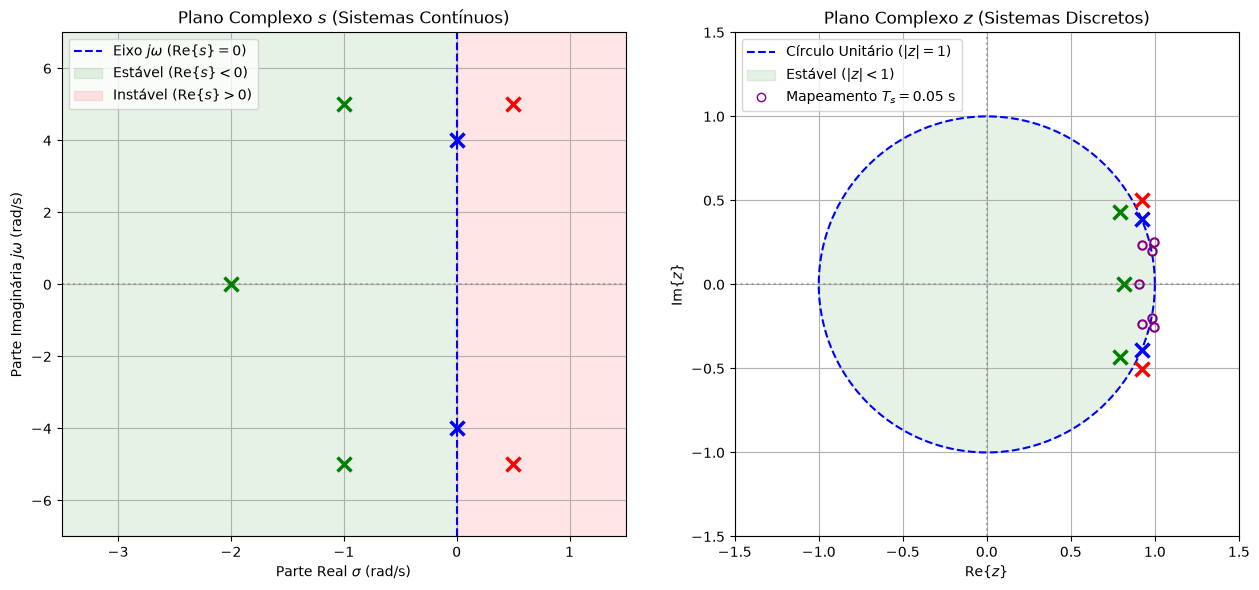

In [3]:
fig, (ax_s, ax_z) = plt.subplots(1, 2, figsize=(13, 6))

# 1. Gráfico no Plano-s
ax_s.axhline(0, color='gray', linestyle=':', alpha=0.6)
ax_s.axvline(0, color='blue', linestyle='--', linewidth=1.5, label=r'Eixo $j\omega$ ($\text{Re}\{s\}=0$)')
ax_s.axvspan(-4, 0, color='green', alpha=0.1, label=r'Estável ($\text{Re}\{s\} < 0$)')
ax_s.axvspan(0, 2, color='red', alpha=0.1, label=r'Instável ($\text{Re}\{s\} > 0$)')

for p in polos_s:
    cor = 'g' if p.real < 0 else ('b' if p.real == 0 else 'r')
    ax_s.plot(p.real, p.imag, 'x', color=cor, markersize=10, markeredgewidth=2.5)

ax_s.set_title(r'Plano Complexo $s$ (Sistemas Contínuos)')
ax_s.set_xlabel(r'Parte Real $\sigma$ (rad/s)')
ax_s.set_ylabel(r'Parte Imaginária $j\omega$ (rad/s)')
ax_s.set_xlim(-3.5, 1.5)
ax_s.set_ylim(-7, 7)
ax_s.grid(True)
ax_s.legend(loc='upper left')

# 2. Gráfico no Plano-z
theta = np.linspace(0, 2 * np.pi, 300)
ax_z.plot(np.cos(theta), np.sin(theta), 'b--', linewidth=1.5, label=r'Círculo Unitário ($|z|=1$)')
ax_z.fill(np.cos(theta), np.sin(theta), color='green', alpha=0.1, label=r'Estável ($|z| < 1$)')
ax_z.axhline(0, color='gray', linestyle=':', alpha=0.6)
ax_z.axvline(0, color='gray', linestyle=':', alpha=0.6)

for pz in polos_z_Ts1:
    cor = 'g' if abs(pz) < 0.999 else ('b' if abs(abs(pz)-1.0) < 0.001 else 'r')
    ax_z.plot(pz.real, pz.imag, 'x', color=cor, markersize=10, markeredgewidth=2.5)

for pz2 in polos_z_Ts2:
    ax_z.plot(pz2.real, pz2.imag, 'o', color='purple', markersize=6, markerfacecolor='none', markeredgewidth=1.5)

# Legenda extra para Ts2
ax_z.plot([], [], 'purple', marker='o', linestyle='None', fillstyle='none', label=r'Mapeamento $T_s = 0.05\text{ s}$')

ax_z.set_title(r'Plano Complexo $z$ (Sistemas Discretos)')
ax_z.set_xlabel(r'$\text{Re}\{z\}$')
ax_z.set_ylabel(r'$\text{Im}\{z\}$')
ax_z.set_xlim(-1.5, 1.5)
ax_z.set_ylim(-1.5, 1.5)
ax_z.set_aspect('equal')
ax_z.grid(True)
ax_z.legend(loc='upper left')

plt.tight_layout()
fig.savefig("grafico_relacao_laplace_transformada_z.png")
plt.show()

## 3. Síntese dos Resultados sobre a Relação entre Laplace e Transformada-Z
- **Transformação Conforme Exponencial**: A relação $z = e^{s T_s}$ mapeia faixas horizontais de largura $\frac{2\pi}{T_s}$ no plano-$s$ em círculos concêntricos no plano-$z$.
- **Mapeamento de Estabilidade**:
  - Polos no semiplano esquerdo contínuo ($\text{Re}\{s\} < 0$) são mapeados rigorosamente para dentro do círculo unitário ($|z| < 1$).
  - Polos no eixo imaginário ($\text{Re}\{s\} = 0$) são mapeados sobre o círculo unitário ($|z| = 1$).
  - Polos no semiplano direito ($\text{Re}\{s\} > 0$) são mapeados para fora do círculo unitário ($|z| > 1$).
- **Influência do Período de Amostragem ($T_s$)**: Reduzir o período de amostragem (ex.: $T_s = 0,05\text{ s}$ vs $T_s = 0,1\text{ s}$) aproxima os polos discretos do ponto $z = 1$ no eixo real positivo, reduzindo a rotação angular $\Omega = \omega T_s$ por amostra.